# Telco Customer Churn Prediction
## Part 1: Data Understanding, Cleaning and Exploratory Analysis

**Objective.** Understand why telecom customers leave (churn), prepare the data for modelling, and identify the main drivers of churn before any model is trained.

**Data source.** *Telco Customer Churn* (IBM sample dataset, a fictional telecommunications company), published on Kaggle: <https://www.kaggle.com/datasets/blastchar/telco-customer-churn>. The dataset has 7,043 customers and 21 columns; each row is one customer and `Churn` is the target.

**Before running.** Download the CSV from Kaggle and save it next to this notebook as `telco.csv`.

**Contents**
1. Data Overview
2. Data Quality Assessment
3. Data Cleaning
4. Train / Test Split
5. Churn Driver Analysis (training set only)
6. Conclusions and Next Steps

---
## 1. Data Overview
### 1.1 Loading the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn مشروع الكلية.csv")

# Categorical text columns (excluding customerID and TotalCharges)
text_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
            "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


### 1.2 Structure and data types

In [2]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

### 1.3 Summary statistics

In [3]:
print(df.describe())
print(df[text_cols].describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
       gender Partner Dependents PhoneService MultipleLines InternetService  \
count    7043    7043       7043         7043          7043            7043   
unique      2       2          2            2             3               3   
top      Male      No         No          Yes            No     Fiber optic   
freq     3555    3641       4933         6361          3390            3096   

       OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV  \
count            7043         7043             7043        7043        7043

### 1.4 Unique values per column

In [4]:
print(df.nunique())

for col in text_cols:
    print(col, "->", df[col].unique())

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64
gender -> ['Female' 'Male']
Partner -> ['Yes' 'No']
Dependents -> ['No' 'Yes']
PhoneService -> ['No' 'Yes']
MultipleLines -> ['No phone service' 'No' 'Yes']
InternetService -> ['DSL' 'Fiber optic' 'No']
OnlineSecurity -> ['No' 'Yes' 'No internet service']
OnlineBackup -> ['Yes' 'No' 'No internet service']
DeviceProtection -> ['No' 'Yes' 'No internet service']
TechSupport -> ['No' 'Yes' 'No internet service']
StreamingTV -> ['No' 'Yes' 'No internet service']


### 1.5 Target variable: `Churn`

object
['No' 'Yes']
2
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


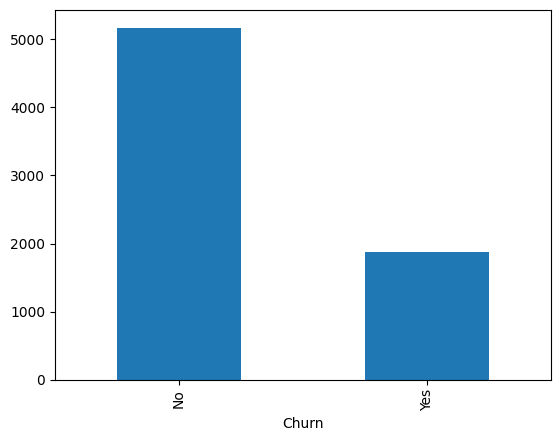

In [5]:
print(df["Churn"].dtype)
print(df["Churn"].unique())
print(df["Churn"].nunique())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))
df["Churn"].value_counts().plot(kind="bar")
plt.show()

**Key observations**
- `TotalCharges` is stored as text and must be converted to numeric.
- `Churn` is stored as text (`Yes` / `No`) and must be encoded as 1 / 0.
- `SeniorCitizen` is numeric (0 / 1) but is categorical in meaning.
- The target is imbalanced (roughly 27% `Yes`), so accuracy alone will not be a reliable metric later.

---
## 2. Data Quality Assessment
Each potential issue is documented below with supporting evidence. **No data is modified in this section**; the fixes are applied in Section 3.

### 2.1 `TotalCharges` stored as text

In [6]:
total_as_number = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad_rows = df[total_as_number.isna()]

print("Values that failed numeric conversion:", len(bad_rows))
print(bad_rows["TotalCharges"].unique())

Values that failed numeric conversion: 11
[' ']


The values that fail numeric conversion are blank strings, which is why the column was read as text.

### 2.2 Extra whitespace in text columns

In [7]:
for col in text_cols + ["customerID", "TotalCharges"]:
    different = (df[col] != df[col].str.strip()).sum()
    if different > 0:
        print(col, "has", different, "values with extra whitespace")

TotalCharges has 11 values with extra whitespace


### 2.3 Redundant category values

`No internet service` and `No phone service` carry the same information that is already present in `InternetService` and `PhoneService`.

In [8]:
print(pd.crosstab(df["InternetService"], df["OnlineSecurity"]))
print(pd.crosstab(df["PhoneService"], df["MultipleLines"]))

OnlineSecurity     No  No internet service   Yes
InternetService                                 
DSL              1241                    0  1180
Fiber optic      2257                    0   839
No                  0                 1526     0
MultipleLines    No  No phone service   Yes
PhoneService                               
No                0               682     0
Yes            3390                 0  2971


`No internet service` appears only in rows where `InternetService = No`, so it is redundant and can be unified with `No`.

### 2.4 Customers with `tenure = 0`

In [9]:
zero_tenure = df[df["tenure"] == 0]
print("Count:", len(zero_tenure))
print(zero_tenure["Churn"].value_counts())
print(zero_tenure[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Count: 11
Churn
No    11
Name: count, dtype: int64
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


**Decision: keep these rows.** They are new customers who have not yet received a bill, so a `TotalCharges` of 0 is the true value. All of them have `Churn = No`, and they are exactly the rows with blank `TotalCharges` found in 2.1.

### 2.5 Duplicate records

In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("customerID unique?", df["customerID"].is_unique)
print("Duplicates after dropping ID:", df.drop(columns="customerID").duplicated().sum())

Duplicate rows: 0
customerID unique? True
Duplicates after dropping ID: 22


Rows that become identical only after removing `customerID` are different customers on the same plan, so they are **not** removed.

### 2.6 Missing values

In [11]:
print(df.isna().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


The check reports no missing values at first sight, but the 11 blank `TotalCharges` entries (whitespace strings) found in 2.1 are hidden missing values.

### 2.7 Outliers (IQR rule)
A value is flagged as an outlier if it falls outside `Q1 - 1.5 x IQR` or `Q3 + 1.5 x IQR`, where `IQR = Q3 - Q1`.

In [12]:
temp = df.copy()
temp["TotalCharges"] = pd.to_numeric(temp["TotalCharges"], errors="coerce")

for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1 = temp[col].quantile(0.25)
    q3 = temp[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = temp[(temp[col] < lower) | (temp[col] > upper)]
    print(col, "| Lower bound:", round(lower, 1), "| Upper bound:", round(upper, 1), "| Outlier count:", len(outliers))

tenure | Lower bound: -60.0 | Upper bound: 124.0 | Outlier count: 0
MonthlyCharges | Lower bound: -46.0 | Upper bound: 171.4 | Outlier count: 0
TotalCharges | Lower bound: -4688.5 | Upper bound: 8884.7 | Outlier count: 0


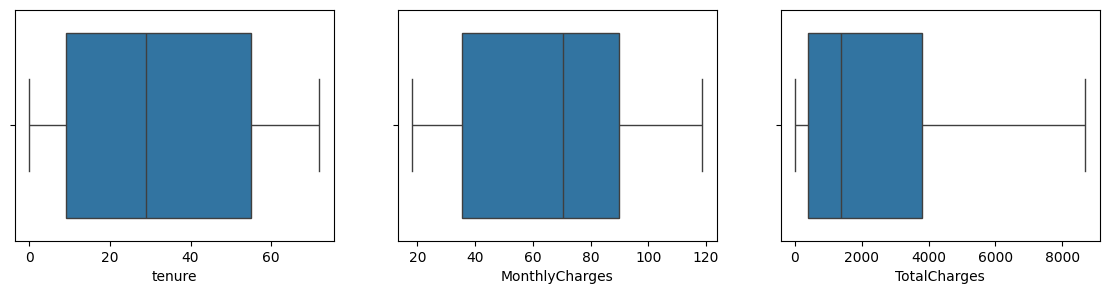

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
sns.boxplot(x=temp["tenure"], ax=axes[0])
sns.boxplot(x=temp["MonthlyCharges"], ax=axes[1])
sns.boxplot(x=temp["TotalCharges"], ax=axes[2])
plt.show()

An outlier count of 0 means that no values need to be removed or capped.

### 2.8 Encoding of `SeniorCitizen` and `Churn`

In [14]:
print(df["SeniorCitizen"].dtype, df["SeniorCitizen"].unique())
print(df["Churn"].unique())

int64 [0 1]
['No' 'Yes']


### 2.9 Summary of issues and decisions

| # | Issue | Decision |
|---|-------|----------|
| 1 | `TotalCharges` stored as text | Convert to numeric |
| 2 | Extra whitespace in text columns | Apply `strip()` as a precaution |
| 3 | `No internet service` / `No phone service` | Unify with `No` |
| 4 | `tenure = 0` | Keep rows; `TotalCharges = 0` |
| 5 | Duplicates | No genuine duplicates |
| 6 | Missing values | Only `TotalCharges` (same rows as issue 4) |
| 7 | Outliers | Based on the IQR result above |
| 8 | `SeniorCitizen` | Keep as 0 / 1 |
| 9 | `Churn` as Yes / No | Encode as 1 / 0 |

---
## 3. Data Cleaning
Cleaning is applied to a copy (`df_clean`) so the original data frame stays untouched.

### 3.1 Convert `TotalCharges` to numeric
Blank values are filled with 0: Section 2.4 showed they belong to customers with `tenure = 0`, so this is a justified business value and not a statistical imputation.

In [15]:
df_clean = df.copy()

# 1) Convert TotalCharges to numeric; customers with tenure=0 get 0
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

print(df_clean["TotalCharges"].dtype)
print(df_clean["TotalCharges"].isna().sum())

float64
0


### 3.2 Strip whitespace and unify redundant categories

In [16]:
# 2) Strip extra whitespace from text columns
for col in text_cols + ["customerID"]:
    df_clean[col] = df_clean[col].str.strip()

# 3) Unify redundant category values
df_clean = df_clean.replace({"No internet service": "No", "No phone service": "No"})

print(pd.crosstab(df_clean["InternetService"], df_clean["OnlineSecurity"]))

OnlineSecurity     No   Yes
InternetService            
DSL              1241  1180
Fiber optic      2257   839
No               1526     0


### 3.3 Drop the identifier and encode the target

`customerID` is only an identifier and carries no predictive information. `Churn` is encoded as 1 (left) and 0 (stayed).

In [17]:
# 4) Drop customerID (identifier only, no predictive information)
df_clean = df_clean.drop(columns="customerID")

# 5) Encode Churn as 1/0
df_clean["Churn"] = df_clean["Churn"].map({"No": 0, "Yes": 1})

print(df_clean["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


### 3.4 Column groups for the preprocessing pipeline
`SeniorCitizen` is already 0 / 1, so it needs no encoding and is passed through unchanged. Numeric columns will be scaled and categorical columns one-hot encoded in the next part.

In [18]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]      # will be scaled with StandardScaler
passthrough_cols = ["SeniorCitizen"]                          # already 0/1, passes through unchanged
cat_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
            "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]   # will be one-hot encoded

### 3.5 Validation of the cleaned data

In [19]:
df_clean.info()
print(df_clean.isna().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


---
## 4. Train / Test Split
The split is performed **before** any step that learns from the data, to prevent data leakage. A stratified split keeps the same churn proportion in both sets, which matters because the target is imbalanced. From this point the test set is held out and is not used until final evaluation.

In [20]:
X = df_clean.drop(columns="Churn")
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

train = X_train.copy()
train["Churn"] = y_train
train.to_csv("train.csv", index=False)

test = X_test.copy()
test["Churn"] = y_test
test.to_csv("test.csv", index=False)

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


---
## 5. Churn Driver Analysis
All analysis in this section uses the **training set only**.

### 5.1 Overall churn rate

Overall churn rate: 0.265


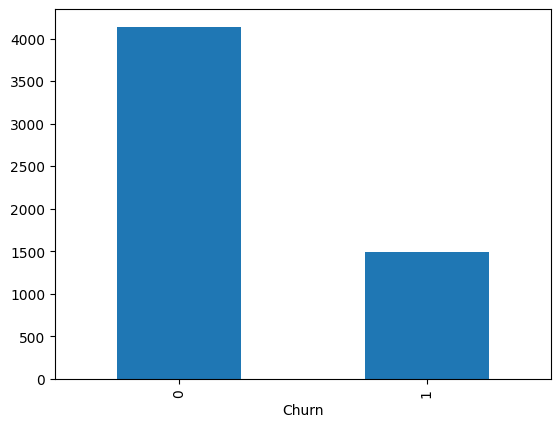

In [21]:
overall = train["Churn"].mean()
print("Overall churn rate:", round(overall, 3))
train["Churn"].value_counts().plot(kind="bar")
plt.show()

### 5.2 Churn rate by customer tenure

tenure_group
0-6      0.522
7-12     0.372
13-24    0.286
25-48    0.202
49-72    0.099
Name: Churn, dtype: float64


/tmp/ipykernel_477/2639461325.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate = train.groupby("tenure_group")["Churn"].mean()


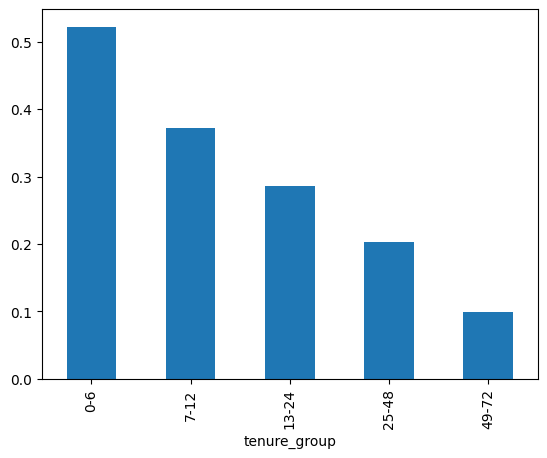

In [22]:
train["tenure_group"] = pd.cut(train["tenure"],
                               bins=[-1, 6, 12, 24, 48, 72],
                               labels=["0-6", "7-12", "13-24", "25-48", "49-72"])

rate = train.groupby("tenure_group")["Churn"].mean()
print(rate.round(3))
rate.plot(kind="bar")
plt.show()

### 5.3 Churn rate by categorical feature

Each bar is the churn rate of one category. The dashed red line marks the overall churn rate, so bars far from the line indicate features with stronger influence.

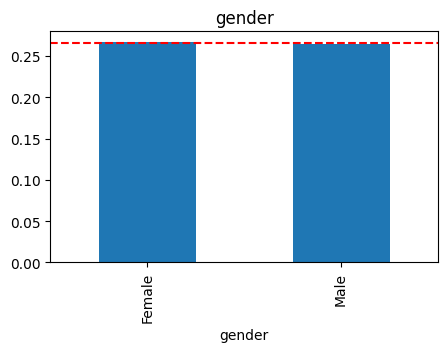

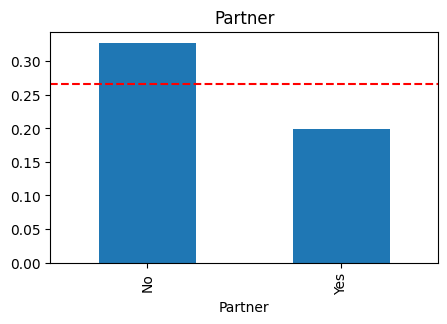

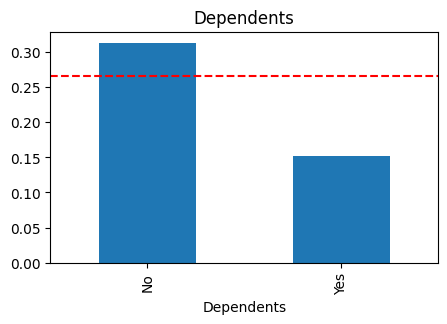

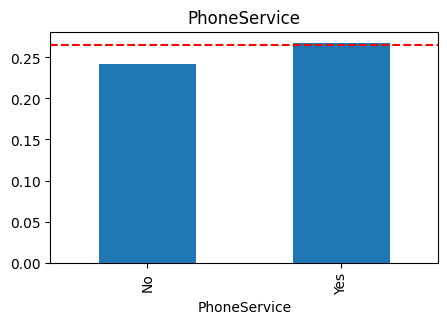

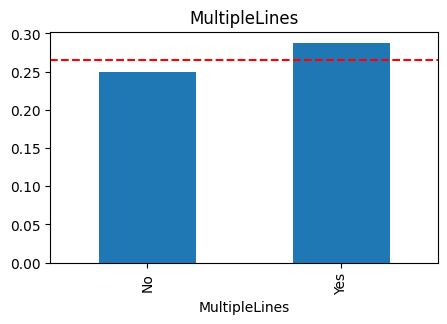

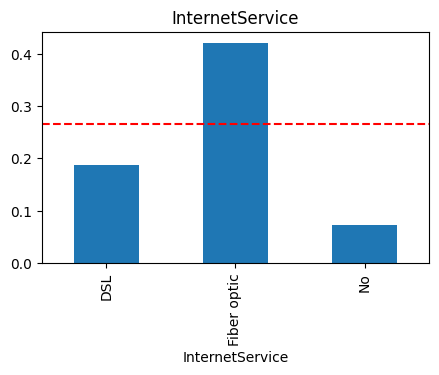

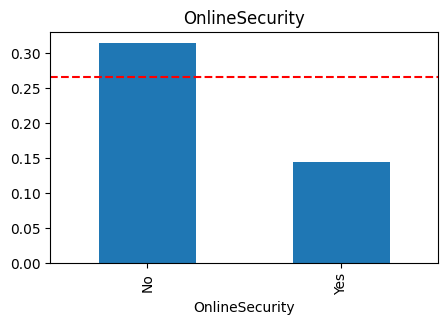

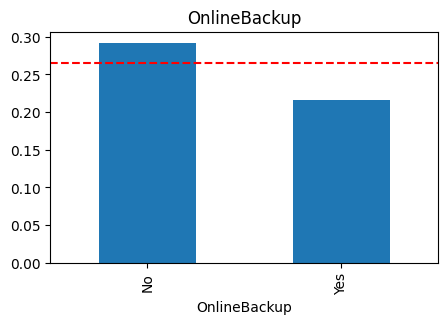

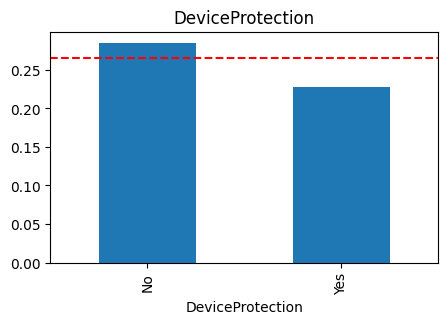

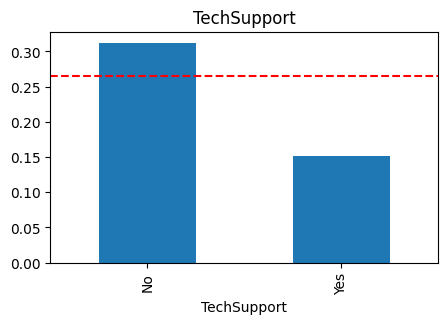

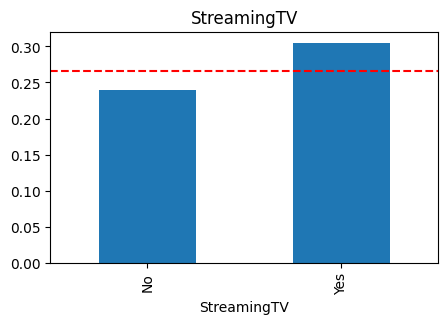

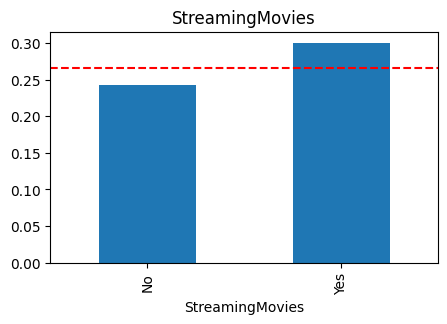

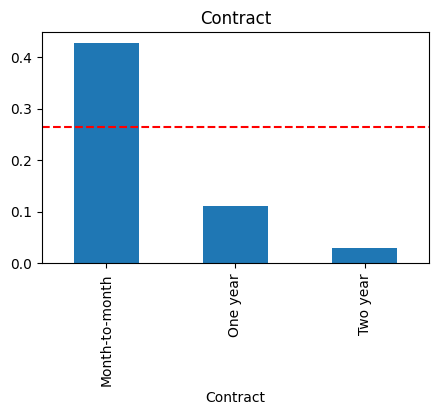

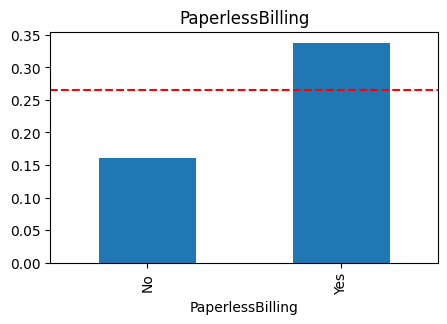

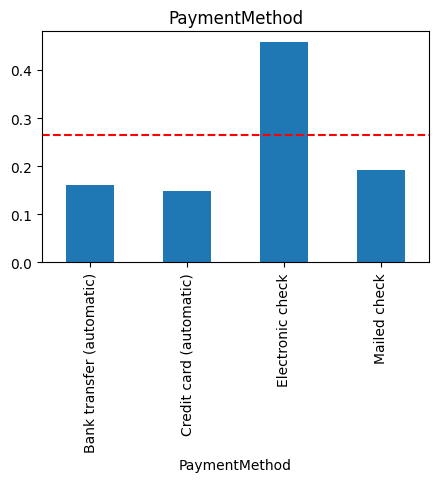

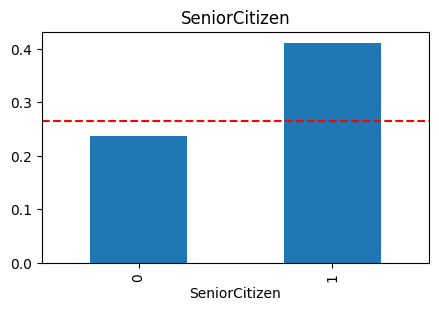

In [23]:
cats = cat_cols + ["SeniorCitizen"]

for col in cats:
    rate = train.groupby(col)["Churn"].mean()
    rate.plot(kind="bar", title=col, figsize=(5, 3))
    plt.axhline(overall, color="red", linestyle="--")   # red line = overall average
    plt.show()

#### Ranking features by spread
The spread is the gap between the highest and lowest churn rate within a feature. A larger spread suggests a stronger effect (a preliminary measure only).

In [24]:
spread = {}
for col in cats:
    rate = train.groupby(col)["Churn"].mean()
    spread[col] = rate.max() - rate.min()

print(pd.Series(spread).sort_values(ascending=False).round(3))

Contract            0.399
InternetService     0.348
PaymentMethod       0.308
PaperlessBilling    0.178
SeniorCitizen       0.174
OnlineSecurity      0.170
Dependents          0.162
TechSupport         0.161
Partner             0.129
OnlineBackup        0.076
StreamingTV         0.066
StreamingMovies     0.058
DeviceProtection    0.057
MultipleLines       0.039
PhoneService        0.026
gender              0.002
dtype: float64


### 5.4 Is price the reason customers leave?
Customers who churn pay more on average. This alone does not prove that price is the cause, because the difference may come from the type of service. The comparison is therefore repeated **within each internet service type**.

Churn
0    61.3
1    74.9
Name: MonthlyCharges, dtype: float64


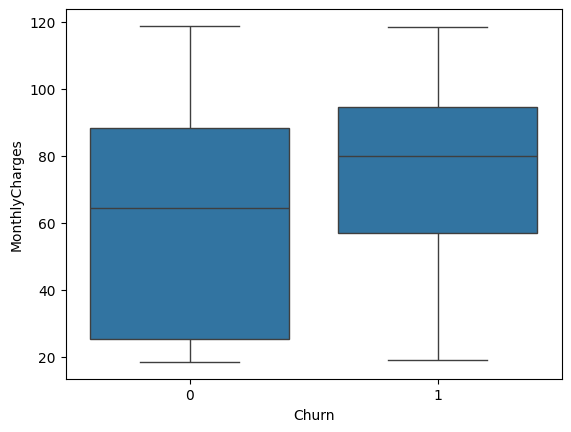

In [25]:
print(train.groupby("Churn")["MonthlyCharges"].mean().round(1))
sns.boxplot(data=train, x="Churn", y="MonthlyCharges")
plt.show()

Churn               0     1
InternetService            
DSL              60.2  49.1
Fiber optic      94.1  88.4
No               21.2  20.5
InternetService
DSL            0.187
Fiber optic    0.421
No             0.072
Name: Churn, dtype: float64


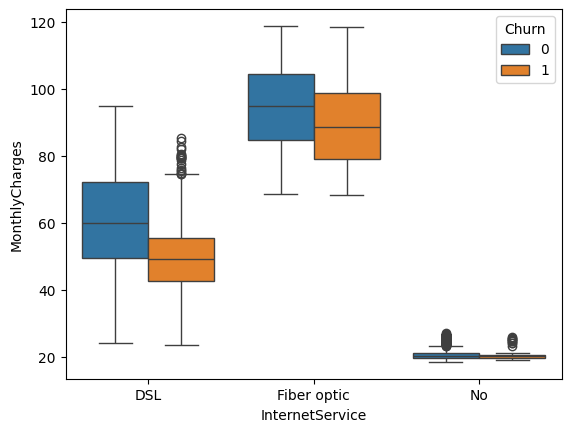

In [26]:
print(train.pivot_table(index="InternetService", columns="Churn", values="MonthlyCharges").round(1))
print(train.groupby("InternetService")["Churn"].mean().round(3))
sns.boxplot(data=train, x="InternetService", y="MonthlyCharges", hue="Churn")
plt.show()

### 5.5 Online services and protection

Customers are compared by the number of add-on services they subscribe to. The Fiber optic group is then examined separately so that like is compared with like.

In [27]:
services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
train["n_services"] = (train[services] == "Yes").sum(axis=1)
print(train.groupby("n_services")["Churn"].mean().round(3))

fiber = train[train["InternetService"] == "Fiber optic"]
print(fiber.groupby("OnlineSecurity")["Churn"].mean().round(3))
print(fiber.groupby("TechSupport")["Churn"].mean().round(3))

n_services
0    0.209
1    0.458
2    0.362
3    0.278
4    0.230
5    0.125
6    0.047
Name: Churn, dtype: float64
OnlineSecurity
No     0.496
Yes    0.219
Name: Churn, dtype: float64
TechSupport
No     0.493
Yes    0.237
Name: Churn, dtype: float64


### 5.6 Demographics and household

In [28]:
for col in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    print(train.groupby(col)["Churn"].mean().round(3))
    print()

gender
Female    0.266
Male      0.264
Name: Churn, dtype: float64

SeniorCitizen
0    0.237
1    0.411
Name: Churn, dtype: float64

Partner
No     0.328
Yes    0.199
Name: Churn, dtype: float64

Dependents
No     0.314
Yes    0.152
Name: Churn, dtype: float64



### 5.7 Revenue lost to churn
The data contains revenue only, with no cost information, so this is lost **revenue**, not lost profit.

In [29]:
lost = train[train["Churn"] == 1]["MonthlyCharges"].sum()
total = train["MonthlyCharges"].sum()

print("Monthly revenue lost:", round(lost), "of", round(total))
print("Share of revenue:", round(lost / total * 100, 1), "%")
print("Share of customers lost:", round(overall * 100, 1), "%")

Monthly revenue lost: 111916 of 365815
Share of revenue: 30.6 %
Share of customers lost: 26.5 %


### 5.8 Churn lift table
Lift is the churn rate of a category divided by the overall churn rate. A value above 1 means the category increases churn; a value below 1 means it decreases churn. After the model is trained, its learned weights will be compared against the direction of these lifts. Categories with fewer than 100 customers are excluded to avoid unreliable estimates.

In [30]:
rows = []
for col in cats:
    rate = train.groupby(col)["Churn"].mean()
    count = train.groupby(col)["Churn"].count()
    for value in rate.index:
        rows.append([col, value, rate[value], count[value]])

lift = pd.DataFrame(rows, columns=["feature", "value", "churn_rate", "n"])
lift["lift"] = (lift["churn_rate"] / overall).round(2)
lift = lift[lift["n"] >= 100]
lift = lift.sort_values("lift", ascending=False)

print(lift.head(8))
print(lift.tail(8))

             feature             value  churn_rate     n  lift
32     PaymentMethod  Electronic check    0.457430  1891  1.72
25          Contract    Month-to-month    0.427466  3102  1.61
11   InternetService       Fiber optic    0.420862  2483  1.59
35     SeniorCitizen                 1    0.410870   920  1.55
29  PaperlessBilling               Yes    0.338037  3331  1.27
2            Partner                No    0.327711  2905  1.23
19       TechSupport                No    0.312422  3985  1.18
4         Dependents                No    0.313527  3955  1.18
             feature                    value  churn_rate     n  lift
28  PaperlessBilling                       No    0.160226  2303  0.60
20       TechSupport                      Yes    0.151607  1649  0.57
5         Dependents                      Yes    0.151876  1679  0.57
31     PaymentMethod  Credit card (automatic)    0.149217  1213  0.56
14    OnlineSecurity                      Yes    0.144177  1623  0.54
26          C

---
## 6. Conclusions and Next Steps

**Main drivers of churn**
- **Short tenure:** churn is 52.2% in the first 6 months and falls to 9.9% for customers with 49 to 72 months.
- **Contract type:** month-to-month customers churn at 42.7%, versus 11.1% (one-year) and 2.9% (two-year).
- **Internet service:** Fiber optic customers churn at 42.1%, versus 18.7% for DSL.
- **Payment method:** electronic check users churn at 45.7%, versus 14.9% for credit card (automatic).

**Is price the cause?** Churners pay more on average (74.9 vs 61.3 per month), but within each internet service type they pay the same or less. The overall gap comes from the larger share of Fiber optic customers among churners, so price alone does not explain churn.

**Protection services.** Among Fiber optic customers, churn is 49.6% without online security and 21.9% with it; it is 49.3% without tech support and 23.7% with it.

**Demographics.** Gender has no effect (26.6% vs 26.4%). Senior citizens (41.1%), customers without a partner (32.8%) and customers without dependents (31.4%) churn more.

**Revenue at risk.** Churners are 26.5% of customers but 30.6% of monthly revenue (111,916 of 365,815).

*Figures above are taken from the executed training-set analysis.*

**Next steps (Part 2):** build the preprocessing pipeline (scaling and one-hot encoding), compare candidate models with cross-validation, handle class imbalance, choose the best model, and apply Explainable AI (XAI) methods (permutation importance and SHAP) to rank the features that most influence churn.

---
# Part 2: Preprocessing, Model Selection and Explainability (XAI)

**Objective.** Build a leak-free preprocessing pipeline, compare candidate models with cross-validation on the training set, choose the best one, and apply Explainable AI (XAI) methods to it to find which features influence churn the most.

**Rules for this part**
- The test set (`test.csv`) stays locked until Section 11. Every modelling decision (model, hyper-parameters, decision threshold) is made with cross-validation on the training set only.
- Every learned step (scaling, encoding, model) is wrapped in one `Pipeline`, so cross-validation refits it inside each fold and nothing leaks from the validation fold.
- Only about 27% of customers churn, so accuracy alone is misleading. The metrics are Recall, F1, ROC-AUC and PR-AUC (average precision). **PR-AUC is the main selection metric** because it does not depend on a decision threshold and is sensitive to the minority class.

**Contents**
7. Preprocessing Pipeline
8. Cross-Validation Setup and Baseline
9. Candidate Models
10. Hyper-parameter Tuning, Model Choice and Decision Threshold
11. Final Evaluation on the Test Set
12. Explainability (XAI)
13. Summary and Next Steps

---
## 7. Preprocessing Pipeline

### 7.1 Reload the saved train and test files
Reloading the CSV files written in Section 4 guarantees that Part 2 uses exactly the same split, and lets this part run on its own.

In [31]:
import numpy as np

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

X_train = train_df.drop(columns="Churn")
y_train = train_df["Churn"]
X_test = test_df.drop(columns="Churn")
y_test = test_df["Churn"]

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


### 7.2 Define the preprocessing
The column groups come from Section 3.4.

| Group | Columns | Transformation | Why |
|---|---|---|---|
| numeric | `tenure`, `MonthlyCharges`, `TotalCharges` | `StandardScaler` | the scales differ a lot (tenure up to 72, TotalCharges in the thousands); Logistic Regression and KNN are sensitive to scale |
| categorical | 15 text columns | `OneHotEncoder` | models need numbers; one 0/1 column per category (binary columns keep a single column through `drop="if_binary"`) |
| passthrough | `SeniorCitizen` | unchanged | already 0 / 1 |

`handle_unknown="ignore"` keeps the encoder safe if a category appears only in new data. The transformer is **not fitted here**: it is fitted inside each cross-validation fold.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
        ("pass", "passthrough", passthrough_cols),
    ])

### 7.3 Inspect the result
This check fits the preprocessor on the training set **for inspection only**. The real fitting happens inside the pipelines below.

The helper `group_of` maps every encoded column back to its original feature (for example `cat__Contract_One year` becomes `Contract`). It is used in Section 12 so that explanations are reported per original feature, not per dummy column.

In [33]:
X_train_prep = preprocessor.fit_transform(X_train)      # inspection only
feature_names = preprocessor.get_feature_names_out()

print("Before:", X_train.shape, "| After:", X_train_prep.shape)
print(list(feature_names))
print(pd.DataFrame(X_train_prep[:, :3], columns=feature_names[:3]).describe().round(2).loc[["mean", "std"]])


def group_of(name):
    # Map an encoded column name back to its original feature
    short = name.split("__", 1)[1]
    for col in cat_cols:
        if short.startswith(col + "_"):
            return col
    return short


feature_groups = [group_of(n) for n in feature_names]
print(pd.Series(feature_groups).nunique(), "original features ->", len(feature_names), "encoded columns")

Before: (5634, 19) | After: (5634, 26)
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Male', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_Yes', 'cat__TechSupport_Yes', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaperlessBilling_Yes', 'cat__PaymentMethod_Bank transfer (automatic)', 'cat__PaymentMethod_Credit card (automatic)', 'cat__PaymentMethod_Electronic check', 'cat__PaymentMethod_Mailed check', 'pass__SeniorCitizen']
      num__tenure  num__MonthlyCharges  num__TotalCharges
mean         -0.0                 -0.0                0.0
std           1.0                  1.0                1.0
19 original features -> 26 encoded columns


---
## 8. Cross-Validation Setup and Baseline

**Stratified 5-fold cross-validation** splits the training set into 5 parts that keep the churn proportion. Each model is trained on 4 parts and scored on the remaining one, 5 times. The average shows how the model performs on unseen customers and the standard deviation shows how stable it is.

The preprocessor is part of the pipeline, so scaling and encoding are learned only from the 4 training parts of each fold.

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}


def run_cv(name, model):
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    for metric in scoring:
        row[metric] = res["test_" + metric].mean()
        row[metric + "_std"] = res["test_" + metric].std()
    return row


def show(results):
    df_res = pd.DataFrame(results)
    out = pd.DataFrame({"model": df_res["model"]})
    for metric in scoring:
        out[metric] = df_res[metric].round(3).astype(str) + " +/- " + df_res[metric + "_std"].round(3).astype(str)
    return out


results = [run_cv("Baseline (always 'stay')", DummyClassifier(strategy="most_frequent"))]
show(results)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (always 'stay'),0.735 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.5 +/- 0.0,0.265 +/- 0.0


**Reading the baseline.** A model that predicts "stay" for everyone gets about 73.5% accuracy but a recall of 0: it finds no churner. Its PR-AUC equals the churn rate (about 0.265). Any real model must beat these numbers on Recall, F1 and PR-AUC; accuracy cannot show that.

---
## 9. Candidate Models

| Model | Idea | Why it is included |
|---|---|---|
| Logistic Regression | weighted sum of the features passed through a sigmoid | simple, fast, directly interpretable coefficients |
| KNN | predicts from the 25 most similar customers | distance-based baseline; shows the effect of scaling |
| Random Forest | many decision trees trained on random samples, votes averaged | captures non-linear effects and interactions, robust |
| Gradient Boosting | trees built one after another, each fixing the previous errors | usually the strongest model on tabular data |

**Class imbalance.** Logistic Regression and Random Forest use `class_weight` so that errors on churners count more. KNN and Gradient Boosting do not have this option; their predictions are compared fairly through PR-AUC and ROC-AUC (which do not depend on the threshold), and the decision threshold is tuned in Section 10.

In [35]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced_subsample", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    results.append(run_cv(name, model))

show(results)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline (always 'stay'),0.735 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.0 +/- 0.0,0.5 +/- 0.0,0.265 +/- 0.0
1,Logistic Regression,0.749 +/- 0.014,0.518 +/- 0.017,0.803 +/- 0.037,0.629 +/- 0.021,0.846 +/- 0.012,0.66 +/- 0.02
2,KNN,0.797 +/- 0.013,0.629 +/- 0.029,0.577 +/- 0.021,0.601 +/- 0.022,0.836 +/- 0.008,0.62 +/- 0.014
3,Random Forest,0.778 +/- 0.013,0.563 +/- 0.02,0.728 +/- 0.032,0.634 +/- 0.022,0.845 +/- 0.01,0.657 +/- 0.02
4,Gradient Boosting,0.801 +/- 0.012,0.661 +/- 0.038,0.518 +/- 0.017,0.581 +/- 0.02,0.847 +/- 0.012,0.665 +/- 0.019


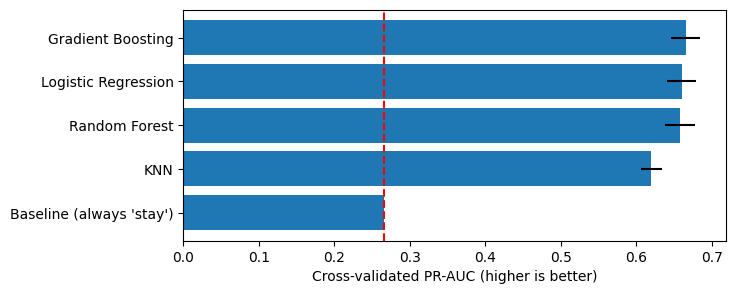

In [36]:
res_df = pd.DataFrame(results).sort_values("pr_auc", ascending=True)
plt.figure(figsize=(7, 3))
plt.barh(res_df["model"], res_df["pr_auc"], xerr=res_df["pr_auc_std"], color="tab:blue")
plt.axvline(y_train.mean(), color="red", linestyle="--")       # red line = churn rate = random model
plt.xlabel("Cross-validated PR-AUC (higher is better)")
plt.show()

**How to read it.** Each bar is the mean PR-AUC over the 5 folds and the thin line is the standard deviation. The red dashed line is the PR-AUC of a model with no skill (the churn rate). A larger bar means a better ranking of customers by churn risk; overlapping error lines mean the difference between two models is within the noise of the folds.

---
## 10. Hyper-parameter Tuning, Model Choice and Decision Threshold

### 10.1 Grid search with the same cross-validation
Each model gets a small grid of hyper-parameters. `GridSearchCV` tries every combination with the same 5 folds and keeps the one with the best mean PR-AUC. Tuning every model gives all candidates the same chance before the final choice.

The tuning score is slightly optimistic because the same folds are used to tune and to compare. The test set, which no decision has touched, gives the honest estimate in Section 11.

In [37]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "KNN": {"model__n_neighbors": [15, 25, 50]},
    "Random Forest": {"model__max_depth": [5, 8, None], "model__min_samples_leaf": [5, 20]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

tuned = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    search = GridSearchCV(pipe, param_grids[name], scoring="average_precision", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(name, "| best PR-AUC:", round(search.best_score_, 3), "| best params:", search.best_params_)

Logistic Regression | best PR-AUC: 0.66 | best params: {'model__C': 1}
KNN | best PR-AUC: 0.633 | best params: {'model__n_neighbors': 50}
Random Forest | best PR-AUC: 0.665 | best params: {'model__max_depth': None, 'model__min_samples_leaf': 20}
Gradient Boosting | best PR-AUC: 0.667 | best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}


### 10.2 Choose the final model
The final model is the one with the highest cross-validated PR-AUC after tuning. If the runner-up is within one standard deviation of the winner, the two are statistically indistinguishable and the simpler, more interpretable model can be preferred; that is a judgement to state in the report.

In [38]:
tuned_table = pd.DataFrame({
    "model": list(tuned),
    "cv_pr_auc": [s.best_score_ for s in tuned.values()],
    "cv_pr_auc_std": [s.cv_results_["std_test_score"][s.best_index_] for s in tuned.values()],
}).sort_values("cv_pr_auc", ascending=False).reset_index(drop=True)
print(tuned_table.round(4))

gap = tuned_table.loc[0, "cv_pr_auc"] - tuned_table.loc[1, "cv_pr_auc"]
print("Gap between the top two:", round(gap, 4), "| std of the winner:", round(tuned_table.loc[0, "cv_pr_auc_std"], 4))

final_name = tuned_table.loc[0, "model"]
final_model = tuned[final_name].best_estimator_
print("Final model:", final_name)

                 model  cv_pr_auc  cv_pr_auc_std
0    Gradient Boosting     0.6668         0.0206
1        Random Forest     0.6654         0.0185
2  Logistic Regression     0.6600         0.0198
3                  KNN     0.6332         0.0186
Gap between the top two: 0.0013 | std of the winner: 0.0206
Final model: Gradient Boosting


### 10.3 Choose the decision threshold
A model outputs a churn probability; a threshold turns it into "will churn" / "will stay". The default 0.5 is not suitable for an imbalanced target. The threshold is chosen from **out-of-fold** probabilities on the training set (each customer is predicted by a model that never saw them), picking the value that maximises F1. If the business prefers to catch more churners, a lower threshold increases Recall at the cost of Precision.

Best threshold: 0.332
Threshold 0.5   -> precision 0.676 | recall 0.527 | F1 0.592
Tuned threshold -> precision 0.568 | recall 0.729 | F1 0.638


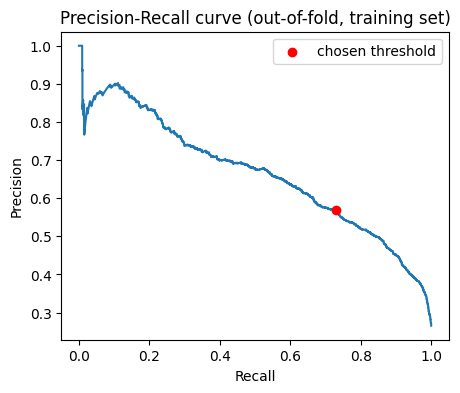

In [39]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * precision * recall / (precision + recall + 1e-12)
best_idx = f1_curve[:-1].argmax()                 # the last point of the curve has no threshold
best_threshold = thresholds[best_idx]

oof_default = (oof_proba >= 0.5).astype(int)
oof_tuned = (oof_proba >= best_threshold).astype(int)
print("Best threshold:", round(best_threshold, 3))
print("Threshold 0.5   -> precision", round(precision_score(y_train, oof_default), 3),
      "| recall", round(recall_score(y_train, oof_default), 3), "| F1", round(f1_score(y_train, oof_default), 3))
print("Tuned threshold -> precision", round(precision_score(y_train, oof_tuned), 3),
      "| recall", round(recall_score(y_train, oof_tuned), 3), "| F1", round(f1_score(y_train, oof_tuned), 3))

plt.figure(figsize=(5, 4))
plt.plot(recall, precision)
plt.scatter(recall[best_idx], precision[best_idx], color="red", zorder=3, label="chosen threshold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve (out-of-fold, training set)")
plt.legend()
plt.show()

---
## 11. Final Evaluation on the Test Set
This is the **first and only time** the test set is used for scoring. The final pipeline was already refitted on the whole training set by `GridSearchCV`. No further tuning is allowed after this step; changing the model after seeing these numbers would turn the test set into a validation set.

                            setting  accuracy  precision  recall    f1  roc_auc  pr_auc
Gradient Boosting @ tuned threshold     0.776      0.560   0.741 0.638    0.845   0.662
            Gradient Boosting @ 0.5     0.800      0.661   0.505 0.573    0.845   0.662
           Baseline (always 'stay')     0.735      0.000   0.000 0.000    0.500   0.265

              precision    recall  f1-score   support

      Stayed       0.89      0.79      0.84      1035
     Churned       0.56      0.74      0.64       374

    accuracy                           0.78      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.78      0.79      1409



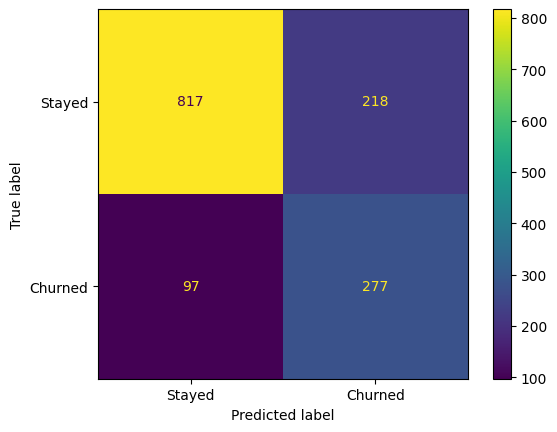

In [40]:
from sklearn.metrics import (average_precision_score, classification_report, ConfusionMatrixDisplay,
                             accuracy_score, roc_auc_score)

test_proba = final_model.predict_proba(X_test)[:, 1]


def evaluate(label, pred, score):
    return {"setting": label,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, score),
            "pr_auc": average_precision_score(y_test, score)}


pred_tuned = (test_proba >= best_threshold).astype(int)
pred_default = (test_proba >= 0.5).astype(int)

final_table = pd.DataFrame([
    evaluate(final_name + " @ tuned threshold", pred_tuned, test_proba),
    evaluate(final_name + " @ 0.5", pred_default, test_proba),
    evaluate("Baseline (always 'stay')", np.zeros(len(y_test), dtype=int), np.zeros(len(y_test))),
])
print(final_table.round(3).to_string(index=False))

print()
print(classification_report(y_test, pred_tuned, target_names=["Stayed", "Churned"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_tuned, display_labels=["Stayed", "Churned"])
plt.show()

**How to read it.** The confusion matrix shows, for the churners in the test set, how many were caught (true positives, bottom right) and how many were missed (false negatives, bottom left), and how many loyal customers would receive an unnecessary offer (false positives, top right). Compare Recall, F1 and PR-AUC with the baseline; accuracy is shown only to demonstrate why it cannot be the selection metric.

---
## 12. Explainability (XAI)

The goal is to find **which features influence the churn decision of the final model the most**. Two complementary XAI methods are applied to the final model:

| Method | Question it answers | Scope |
|---|---|---|
| Permutation importance | how much does the model's performance drop when one feature is shuffled? | global, works with any model |
| SHAP | how much did each feature push the churn probability of each customer up or down? | local (one customer) and global (average over customers) |

Both are computed on the **test set**, which the model did not train on, so the explanation reflects what the model does on unseen customers. Results are reported per **original feature**: the dummy columns created by one-hot encoding are merged back (Section 7.3).

*Important:* XAI explains what the **model** relies on. It does not prove that a feature causes churn in the real world.

### 12.1 Permutation importance
Each original column of the test set is shuffled several times and the drop in PR-AUC is recorded. Because the whole pipeline is shuffled-and-scored, the result is directly at the level of original features. A larger drop means a more important feature.

         feature  importance    std
          tenure      0.1467 0.0161
        Contract      0.0856 0.0094
 InternetService      0.0787 0.0134
  MonthlyCharges      0.0204 0.0073
     TechSupport      0.0155 0.0048
    PhoneService      0.0074 0.0036
  OnlineSecurity      0.0074 0.0029
    TotalCharges      0.0069 0.0032
PaperlessBilling      0.0067 0.0054
   PaymentMethod      0.0055 0.0051


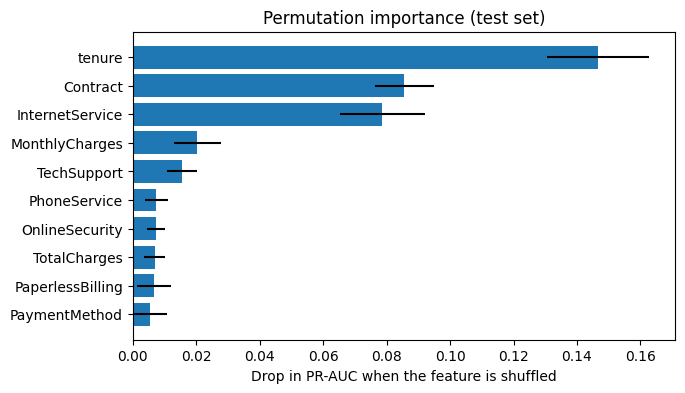

In [41]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=42, n_jobs=-1)

perm_df = pd.DataFrame({"feature": X_test.columns,
                        "importance": perm.importances_mean,
                        "std": perm.importances_std}).sort_values("importance", ascending=False)
print(perm_df.round(4).head(10).to_string(index=False))

top = perm_df.head(10).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="tab:blue")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.show()

### 12.2 SHAP values
SHAP gives every feature of every customer a contribution: positive values push the prediction towards churn, negative values towards staying. The contributions of one customer add up to the difference between that customer's prediction and the average prediction.

The explainer is chosen by model type: `LinearExplainer` for Logistic Regression, `TreeExplainer` for Random Forest and Gradient Boosting, and a (slower) model-agnostic `KernelExplainer` on a sample for any other model. The units differ by model (log-odds for Logistic Regression and Gradient Boosting, probability for Random Forest), so SHAP values are used to **rank features and read directions**, not to compare magnitudes across different models.

In [42]:
try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

prep = final_model.named_steps["prep"]
clf = final_model.named_steps["model"]

X_bg = prep.transform(X_train)        # background data = training distribution
X_ex = prep.transform(X_test)         # customers to explain

if isinstance(clf, LogisticRegression):
    explainer = shap.LinearExplainer(clf, X_bg)
    sv = explainer.shap_values(X_ex)
elif isinstance(clf, (RandomForestClassifier, GradientBoostingClassifier)):
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(X_ex)
else:
    explainer = shap.KernelExplainer(lambda d: clf.predict_proba(d)[:, 1], shap.sample(X_bg, 100))
    sv = explainer.shap_values(X_ex[:300])
    X_ex = X_ex[:300]

# Different shap versions return a list (one array per class) or a 3-D array; keep the churn class
if isinstance(sv, list):
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, 1]
print("SHAP matrix:", sv.shape, "= customers x encoded columns")

SHAP matrix: (1409, 26) = customers x encoded columns


**Merge the dummy columns back into original features.** The SHAP values are additive, so the contribution of an original feature (for example `Contract`) is the sum of the contributions of its dummy columns. The global importance is the mean absolute contribution over customers.

Contract            0.6203
tenure              0.4727
InternetService     0.4333
PaymentMethod       0.1622
PaperlessBilling    0.1262
MonthlyCharges      0.1187
TechSupport         0.1024
OnlineSecurity      0.0907
MultipleLines       0.0855
TotalCharges        0.0687
dtype: float64


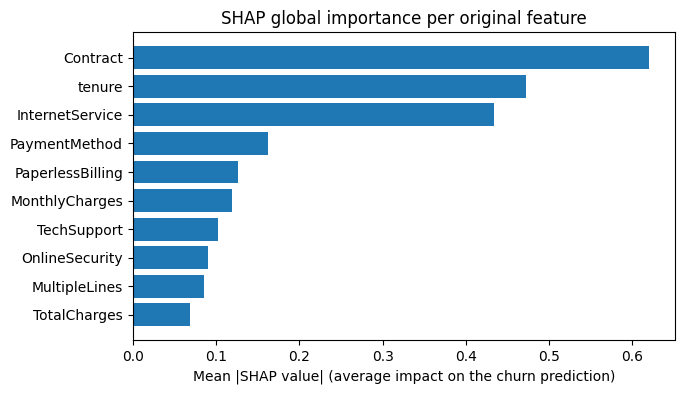

In [43]:
sv_df = pd.DataFrame(sv, columns=feature_names)
sv_feat = pd.DataFrame({
    group: sv_df[[n for n, g in zip(feature_names, feature_groups) if g == group]].sum(axis=1)
    for group in dict.fromkeys(feature_groups)})

shap_importance = sv_feat.abs().mean().sort_values(ascending=False)
print(shap_importance.round(4).head(10))

top = shap_importance.head(10).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color="tab:blue")
plt.xlabel("Mean |SHAP value| (average impact on the churn prediction)")
plt.title("SHAP global importance per original feature")
plt.show()

**Detailed view.** The summary plot below works at the level of the encoded columns. Each dot is one customer. The horizontal position is the SHAP value (right = pushes towards churn) and the colour is the value of the feature (red = high, blue = low; for a 0/1 column red means the category is present).

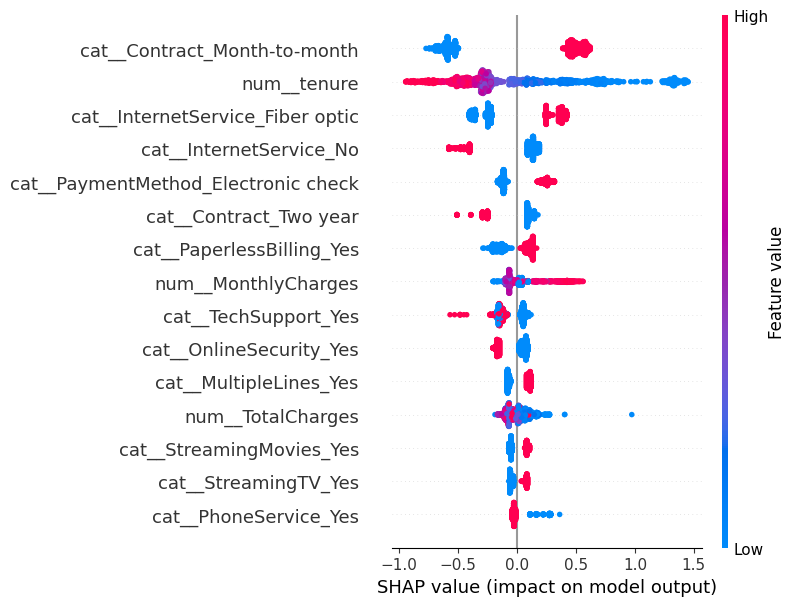

In [44]:
shap.summary_plot(sv, X_ex, feature_names=list(feature_names), max_display=15, show=False)
plt.gcf().set_size_inches(8, 6)
plt.show()

### 12.3 Do the two XAI methods agree?
Two independent methods that rank the features in a similar order make the conclusion more reliable. The Spearman correlation measures the agreement of the two rankings (1 = identical order).

In [45]:
from scipy.stats import spearmanr

compare = pd.DataFrame({"permutation_rank": perm_df.set_index("feature")["importance"].rank(ascending=False),
                        "shap_rank": shap_importance.rank(ascending=False)}).sort_values("shap_rank")
print(compare.head(10).astype(int))
print("Spearman correlation of the two rankings:", round(spearmanr(compare["permutation_rank"], compare["shap_rank"])[0], 3))

                  permutation_rank  shap_rank
Contract                         2          1
tenure                           1          2
InternetService                  3          3
PaymentMethod                   10          4
PaperlessBilling                 9          5
MonthlyCharges                   4          6
TechSupport                      5          7
OnlineSecurity                   7          8
MultipleLines                   14          9
TotalCharges                     8         10
Spearman correlation of the two rankings: 0.786


### 12.4 Does the model agree with the exploratory analysis?
Section 5 produced expectations from the lift table (for example month-to-month contracts increase churn, a long tenure decreases it). Here the direction learned by the model is compared with them: for every encoded column, the **direction** is the sign of the correlation between the feature value and its SHAP value (positive = the feature pushes towards churn). Only categories whose lift is clearly away from 1 (above 1.1 or below 0.9) and `tenure` (Section 5.2) have an expectation. `MonthlyCharges` and `TotalCharges` have none because Section 5.4 showed that price alone is not a clear driver.

In [46]:
lift_lookup = {(r.feature, str(r.value)): r.lift for r in lift.itertuples()}

rows = []
for j, name in enumerate(feature_names):
    x, s = X_ex[:, j], sv[:, j]
    corr = np.corrcoef(x, s)[0, 1] if x.std() > 0 and s.std() > 0 else 0.0
    model_dir = "increase" if corr > 0.05 else ("decrease" if corr < -0.05 else "flat")

    group = feature_groups[j]
    expected = None
    if name == "num__tenure":
        expected = "decrease"
    elif name.startswith("cat__"):
        value = name.split("__", 1)[1][len(group) + 1:]
        lift_value = lift_lookup.get((group, value))
        if lift_value is not None and lift_value > 1.1:
            expected = "increase"
        elif lift_value is not None and lift_value < 0.9:
            expected = "decrease"
    elif name == "pass__SeniorCitizen":
        expected = "increase"          # lift 1.55 for SeniorCitizen = 1 (Section 5.8)

    rows.append({"encoded column": name.split("__", 1)[1], "EDA expects": expected,
                 "model direction": model_dir, "mean |SHAP|": np.abs(s).mean()})

direction = pd.DataFrame(rows)
direction["agree"] = np.where(direction["EDA expects"].isna(), None,
                              direction["EDA expects"] == direction["model direction"])
direction = direction.sort_values("mean |SHAP|", ascending=False)
print(direction.head(15).round(4).to_string(index=False))

checked = direction[direction["EDA expects"].notna()]
print()
print("Columns with an EDA expectation:", len(checked), "| model agrees on:", int((checked["agree"] == True).sum()))
print("Disagreements:", list(checked.loc[checked["agree"] == False, "encoded column"]))

                encoded column EDA expects model direction  mean |SHAP| agree
       Contract_Month-to-month    increase        increase       0.5471  True
                        tenure    decrease        decrease       0.4727  True
   InternetService_Fiber optic    increase        increase       0.3176  True
            InternetService_No    decrease        decrease       0.2039  True
PaymentMethod_Electronic check    increase        increase       0.1622  True
             Contract_Two year    decrease        decrease       0.1452  True
          PaperlessBilling_Yes    increase        increase       0.1262  True
                MonthlyCharges        None        increase       0.1187  None
               TechSupport_Yes    decrease        decrease       0.1024  True
            OnlineSecurity_Yes    decrease        decrease       0.0907  True
             MultipleLines_Yes        None        increase       0.0855  None
                  TotalCharges        None        decrease      

Where the model disagrees with the exploratory analysis, the usual reason is that features are correlated (for example `TotalCharges` grows with `tenure`, and `InternetService` is tied to `MonthlyCharges`), so the model shares the credit between them. That is expected and worth stating in the report.

### 12.5 Explaining individual customers (local SHAP)
The same SHAP values explain one customer. Below, the customer with the highest and the lowest predicted churn probability in the test set are shown: each bar is the contribution of one original feature (red = pushes towards churn, blue = towards staying).

Highest predicted risk -> customer profile:
tenure                            1
Contract             Month-to-month
InternetService         Fiber optic
MonthlyCharges                 95.1
PaymentMethod      Electronic check
TotalCharges                   95.1
SeniorCitizen                     1
MultipleLines                   Yes

Lowest predicted risk -> customer profile:
Contract                             Two year
tenure                                     72
InternetService                            No
TechSupport                                No
PaperlessBilling                           No
PaymentMethod       Bank transfer (automatic)
TotalCharges                          1322.85
MultipleLines                              No



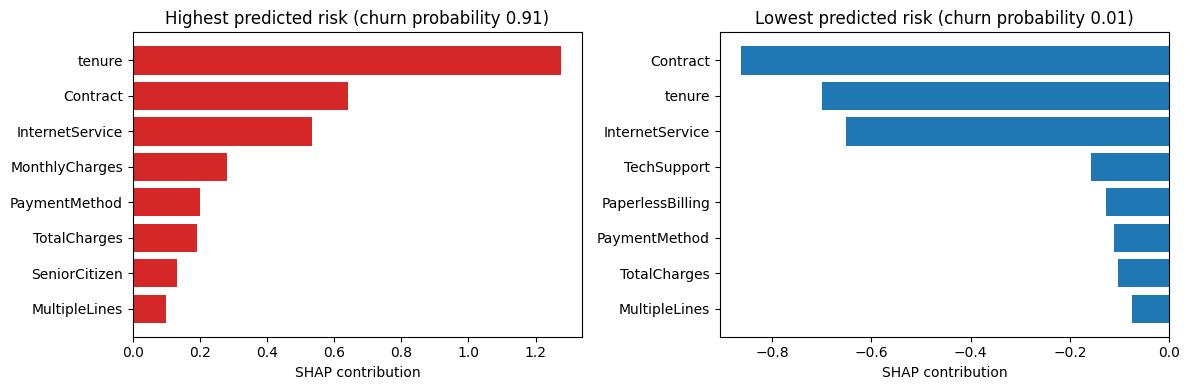

In [47]:
proba_test = final_model.predict_proba(X_test)[:, 1]
if len(sv_feat) < len(X_test):                    # KernelExplainer case: only the first rows were explained
    proba_test = proba_test[:len(sv_feat)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, idx) in zip(axes, [("Highest predicted risk", int(proba_test.argmax())),
                                   ("Lowest predicted risk", int(proba_test.argmin()))]):
    contrib = sv_feat.iloc[idx]
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(8).iloc[::-1]
    ax.barh(contrib.index, contrib.values, color=["tab:red" if v > 0 else "tab:blue" for v in contrib.values])
    ax.set_title(label + " (churn probability " + str(round(proba_test[idx], 2)) + ")")
    ax.set_xlabel("SHAP contribution")
    print(label, "-> customer profile:")
    print(X_test.iloc[idx][contrib.index[::-1]].to_string())
    print()
plt.tight_layout()
plt.show()

---
## 13. Summary and Next Steps

In [48]:
print("Final model:", final_name, "| tuned parameters:", tuned[final_name].best_params_)
print("Cross-validated PR-AUC:", round(tuned_table.loc[0, "cv_pr_auc"], 3), "| test PR-AUC:", round(final_table.loc[0, "pr_auc"], 3))
print("Test recall:", round(final_table.loc[0, "recall"], 3), "| test F1:", round(final_table.loc[0, "f1"], 3),
      "| decision threshold:", round(best_threshold, 3))
print()
print("Top 5 features by SHAP     :", list(shap_importance.head(5).index))
print("Top 5 by permutation       :", list(perm_df["feature"].head(5)))

Final model: Gradient Boosting | tuned parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 200}
Cross-validated PR-AUC: 0.667 | test PR-AUC: 0.662
Test recall: 0.741 | test F1: 0.638 | decision threshold: 0.332

Top 5 features by SHAP     : ['Contract', 'tenure', 'InternetService', 'PaymentMethod', 'PaperlessBilling']
Top 5 by permutation       : ['tenure', 'Contract', 'InternetService', 'MonthlyCharges', 'TechSupport']


**What to write in the report (use the numbers printed above)**
1. The selected model, its tuned parameters, and why it was chosen (highest cross-validated PR-AUC, compared with the other candidates and with the baseline).
2. The test-set Recall, F1 and PR-AUC at the tuned threshold, and the confusion matrix in business terms (churners caught, churners missed, unnecessary offers).
3. The most influential features according to SHAP and permutation importance, whether the two methods agree, and whether the model's directions agree with the exploratory analysis of Section 5.
4. The limits: XAI explains the model, not causation; correlated features share importance; the dataset is a sample from a fictional company; revenue is not profit.

**Next steps**
- Use the individual SHAP explanations to flag high-risk customers and the feature that pushes each one towards churn.
- Segment customers with K-Means and match an offer to each risk factor (for example a contract-upgrade offer for month-to-month customers, a free security or tech-support trial for Fiber optic customers without protection).
- Final report and presentation.

---
# Part 3: Customer Segmentation with K-Means and Retention Offers

**Objective.** Group customers into a few segments with similar profiles (K-Means, an unsupervised algorithm), measure the churn rate of every segment, and attach a retention offer to each one. The model of Part 2 answers *who* is likely to leave and *why*; the segments answer *what to offer* to each group.

**Rules for this part**
- K-Means never sees the `Churn` column. Churn is used only afterwards, to describe the segments.
- The same preprocessing as Part 2 is used (scaled numeric columns + one-hot categorical columns), so that distances are comparable.
- The number of segments `k` is chosen with the elbow curve and the silhouette score, then checked for business meaning.

## 14. K-Means Segmentation

### 14.1 Prepare the data
All 7,043 customers (train + test) are used because this is a description of the customer base, not a prediction. Preprocessing is fitted without looking at `Churn`.

In [49]:
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

all_df = pd.concat([train_df, test_df], ignore_index=True)
X_all = all_df.drop(columns="Churn")
y_all = all_df["Churn"]

seg_prep = clone(preprocessor)
Z = seg_prep.fit_transform(X_all)
print("Customers:", Z.shape[0], "| encoded columns:", Z.shape[1], "| overall churn rate:", round(y_all.mean(), 3))

Customers: 7043 | encoded columns: 26 | overall churn rate: 0.265


### 14.2 Choose the number of segments
- **Inertia (elbow):** the total squared distance of customers to their segment centre. It always decreases with `k`; look for the point where the decrease slows down.
- **Silhouette score:** from -1 to 1, how well each customer fits its own segment compared with the nearest other one. Higher is better.

`n_init=10` repeats the algorithm with 10 random starts and keeps the best, because K-Means can stop in a poor local solution. The silhouette is computed on a random sample of 3,000 customers to keep it fast.

 k  inertia  silhouette
 2  39743.0       0.248
 3  33720.0       0.204
 4  30530.0       0.195
 5  28408.0       0.181
 6  26738.0       0.173
 7  25561.0       0.157
 8  24660.0       0.155


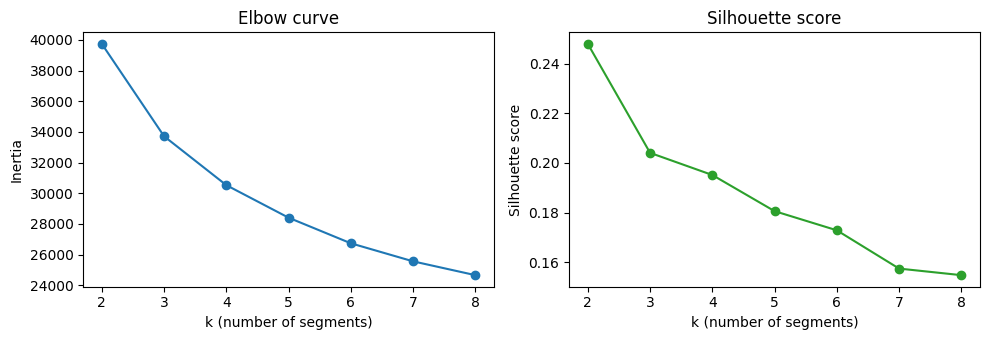

In [50]:
k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=42))

k_table = pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias, 0), "silhouette": np.round(silhouettes, 3)})
print(k_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_xlabel("k (number of segments)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow curve")
axes[1].plot(list(k_values), silhouettes, marker="o", color="tab:green")
axes[1].set_xlabel("k (number of segments)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
plt.tight_layout()
plt.show()

**Choosing `k`.** A business needs a handful of segments it can act on, so the rule used here is: the `k` between 3 and 6 with the highest silhouette score. Change `K` manually in the next cell if the elbow curve or the segment meaning suggests another value.

In [51]:
candidates = k_table[(k_table["k"] >= 3) & (k_table["k"] <= 6)]
K = int(candidates.loc[candidates["silhouette"].idxmax(), "k"])
print("Chosen number of segments K =", K)

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
segments = pd.Series(kmeans.labels_, name="segment")
print(segments.value_counts().sort_index().to_string())

Chosen number of segments K = 3
segment
0    1842
1    2214
2    2987


### 14.3 Visualise the segments
K-Means works in 26 dimensions, which cannot be drawn. PCA projects the customers onto the two directions that keep most of the variance, only for display. The segments are not computed from this picture.

Variance kept by the 2 components: [0.369 0.168] | total: 0.537


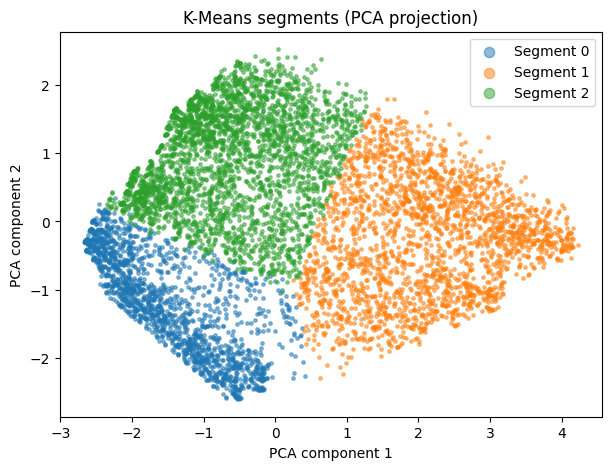

In [52]:
pca = PCA(n_components=2, random_state=42)
Z2 = pca.fit_transform(Z)
print("Variance kept by the 2 components:", pca.explained_variance_ratio_.round(3), "| total:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(7, 5))
for s in range(K):
    mask = (segments == s).values
    plt.scatter(Z2[mask, 0], Z2[mask, 1], s=6, alpha=0.5, label="Segment " + str(s))
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("K-Means segments (PCA projection)")
plt.legend(markerscale=3)
plt.show()

### 14.4 Profile every segment
Now `Churn` and the original (unscaled) columns are used to describe each segment: its size, churn rate, lift over the overall rate, and the typical profile.

In [53]:
prof = X_all.copy()
prof["Churn"] = y_all.values
prof["segment"] = segments.values

profile = prof.groupby("segment").agg(
    customers=("Churn", "size"),
    churn_rate=("Churn", "mean"),
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    pct_senior=("SeniorCitizen", "mean"),
)
profile["share_of_customers"] = profile["customers"] / len(prof)
profile["lift"] = profile["churn_rate"] / y_all.mean()
profile["pct_month_to_month"] = prof.groupby("segment")["Contract"].apply(lambda s: (s == "Month-to-month").mean())
profile["pct_two_year"] = prof.groupby("segment")["Contract"].apply(lambda s: (s == "Two year").mean())
profile["pct_fiber"] = prof.groupby("segment")["InternetService"].apply(lambda s: (s == "Fiber optic").mean())
profile["pct_no_internet"] = prof.groupby("segment")["InternetService"].apply(lambda s: (s == "No").mean())
profile["pct_tech_support"] = prof.groupby("segment")["TechSupport"].apply(lambda s: (s == "Yes").mean())
profile["pct_online_security"] = prof.groupby("segment")["OnlineSecurity"].apply(lambda s: (s == "Yes").mean())
profile["pct_electronic_check"] = prof.groupby("segment")["PaymentMethod"].apply(lambda s: (s == "Electronic check").mean())
profile["pct_dependents"] = prof.groupby("segment")["Dependents"].apply(lambda s: (s == "Yes").mean())

profile = profile.sort_values("churn_rate", ascending=False)
shown = profile.copy()
for col in shown.columns:
    if col.startswith("pct_") or col in ("churn_rate", "share_of_customers"):
        shown[col] = (shown[col] * 100).round(1)
print(shown.round(2).T.to_string())

segment                     2        1        0
customers             2987.00  2214.00  1842.00
churn_rate              46.60    14.30     8.70
avg_tenure              14.53    58.32    30.11
avg_monthly             71.79    89.34    23.83
pct_senior              20.90    19.80     4.30
share_of_customers      42.40    31.40    26.20
lift                     1.75     0.54     0.33
pct_month_to_month      90.10    22.80    36.90
pct_two_year             1.50    43.40    37.40
pct_fiber               57.90    61.70     0.00
pct_no_internet          0.00     0.00    82.80
pct_tech_support        22.20    57.40     6.00
pct_online_security     22.40    55.20     6.90
pct_electronic_check    53.50    27.90     8.00
pct_dependents          18.80    34.90    42.10


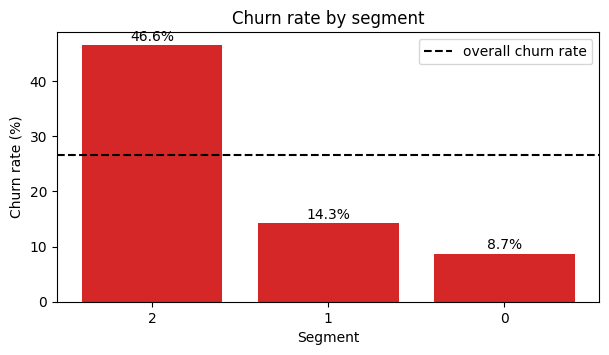

In [54]:
plt.figure(figsize=(7, 3.5))
order = profile.index.astype(str)
plt.bar(order, profile["churn_rate"] * 100, color="tab:red")
plt.axhline(y_all.mean() * 100, color="black", linestyle="--", label="overall churn rate")
for i, v in enumerate(profile["churn_rate"] * 100):
    plt.text(i, v + 0.8, str(round(v, 1)) + "%", ha="center")
plt.xlabel("Segment")
plt.ylabel("Churn rate (%)")
plt.title("Churn rate by segment")
plt.legend()
plt.show()

**How to read it.** A segment is a group of customers who look alike. The important columns are `churn_rate` and `lift` (how many times the overall churn rate), together with the profile columns that explain *why* the segment behaves that way. Give every segment a short business name based on its profile.

### 14.5 Attach a retention offer to every segment
The offers follow the findings of the earlier sections, not new assumptions: month-to-month contracts, electronic check, Fiber without protection services and short tenure were the strongest risk drivers (Section 5 and the XAI results of Section 12). A rule is triggered when the segment is clearly more exposed to a driver than the whole customer base (for the Fiber rule: mostly Fiber customers, and fewer than half of them have TechSupport). Only segments with above-average churn (lift above 1) receive a retention offer; the segments with the highest churn get the first priority.

In [55]:
overall = {
    "pct_month_to_month": (X_all["Contract"] == "Month-to-month").mean(),
    "pct_electronic_check": (X_all["PaymentMethod"] == "Electronic check").mean(),
    "pct_fiber": (X_all["InternetService"] == "Fiber optic").mean(),
    "pct_tech_support": (X_all["TechSupport"] == "Yes").mean(),
    "avg_tenure": X_all["tenure"].mean(),
}


def suggest_offers(r):
    if r["lift"] <= 1:                       # churn below average: no retention discount
        return ["low risk: loyalty rewards and upsell, no retention discount needed"]
    offers = []
    if r["pct_month_to_month"] > overall["pct_month_to_month"] + 0.10:
        offers.append("discount for moving to a 1-year or 2-year contract")
    if r["pct_fiber"] > overall["pct_fiber"] + 0.10 and r["pct_tech_support"] < 0.5:
        offers.append("free 3-month TechSupport / OnlineSecurity bundle for Fiber customers")
    if r["pct_electronic_check"] > overall["pct_electronic_check"] + 0.10:
        offers.append("small bill credit for switching to automatic payment")
    if r["avg_tenure"] < overall["avg_tenure"] * 0.6:
        offers.append("onboarding programme and a check-in call during the first 6 months")
    if not offers:
        offers.append("low risk: loyalty rewards and upsell, no retention discount needed")
    return offers


priority = profile[["customers", "share_of_customers", "churn_rate", "lift"]].copy()
priority["lost_customers_estimate"] = (priority["customers"] * priority["churn_rate"]).round(0)
priority["suggested_offers"] = [" | ".join(suggest_offers(profile.loc[s])) for s in priority.index]
pd.set_option("display.max_colwidth", 200)
print(priority.round(3).to_string())

         customers  share_of_customers  churn_rate   lift  lost_customers_estimate                                                                                                                                                                                                                                       suggested_offers
segment                                                                                                                                                                                                                                                                                                                                  
2             2987               0.424       0.466  1.755                   1391.0  discount for moving to a 1-year or 2-year contract | free 3-month TechSupport / OnlineSecurity bundle for Fiber customers | small bill credit for switching to automatic payment | onboarding programme and a check-in call during the first 6 months
1         

---
## 15. Final Summary of the Project

| Stage | Result |
|---|---|
| EDA | churn is driven by short tenure, month-to-month contract, Fiber optic and electronic check |
| Model | the best tuned model by cross-validated PR-AUC (Section 10) |
| XAI | the features with the largest impact on churn (Section 12) |
| Segmentation | K-Means segments with their churn rate and offer (Section 14) |

The next step outside this notebook is a pilot: offer the matching incentive to the highest-risk segment for a few months, keep a control group without the offer, and compare the churn rates to measure the real effect.